# ¡Hola Fabian!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [33]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np

### Cargar Dataset

In [34]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv') 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [35]:
# mostrar las primeras 5 fila
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo. La carga inicial cumple correctamente con lo solicitado: se importa el dataset, se revisan sus dimensiones, tipos de datos y valores nulos mediante `info()`, y se muestran las primeras filas. Esto permite validar correctamente la estructura del conjunto de datos antes de iniciar la preparación.

</div>

## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Respuesta:

En la columna edad- Cambio: Convertir a entero (int)=Aparece como 44.0, 36.0, 46.0, etc. Si no existen edades decimales, debería almacenarse como 44, 36, 46.

En la columna miembro_premium- Cambio:Convertir a categórica/booleana = Los valores 0 y 1 representan pertenencia o no al programa Premium.

En la columna abandono- Cambio: Convertir a categórica/booleana= Los valores 0 y 1 representan si el cliente abandonó o no.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
visitas_mes
nivel_ingresos
compras_mes
gastos_publicidad_dirigida
satisfaccion
miembro_premium
abandono
ingreso_anual

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .
id_cliente                   object 
edad                        float64
nivel_ingreso                float64
visitas_mes                  int64  
compras_mes                  int64  
gasto_publicidad_dirigida    float64
satisfaccion                 float64
miembro_premium              int64  
abandono                     int64  
tipo_dispositivo             object 
region                       object 
ingreso_anual                float64

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [36]:
# Corregir el tipo de dato

df["edad"] = df["edad"].astype("int64")


df["miembro_premium"] = df["miembro_premium"].astype(bool)
df["abandono"] = df["abandono"].astype(bool)

In [37]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  bool   
 8   abandono                   15000 non-null  bool   
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: bool(2), float64(4), int64(3), object(3)
memory usage: 1.2+ MB


#### Explorar variables numéricas

In [38]:
# Estadísticas descriptivas de variables numéricas

variables_numericas = df.select_dtypes(include="number").columns


estadisticas = df[variables_numericas].describe()


estadisticas

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas
Respuesta:
edad: La media (38.26 años) y la mediana / 50% (38.00 años) coinciden casi perfectamente, lo que indica una distribución de edad muy simétrica (entre los 18 y los 75 años).

nivel_ingreso: El valor mínimo registrado es de 8,000.00, mientras que el máximo alcanza los 74,790.84, con un promedio de 30,019.70.

visitas_mes: En promedio los usuarios visitan el sitio 10.03 veces al mes, alcanzando un máximo de 25 visitas.

compras_mes: Más del 25% de los registros no realizaron ninguna compra (cuartil 25% es 0.00), y el promedio general de compras mensuales es bajo (1.21).

gasto_publicidad_dirigida: Presenta un valor mínimo de 0.00 y un máximo de 75.51, con un gasto medio de 20.15 por usuario.

satisfaccion: La mediana es de 3.60 sobre un rango que va de un mínimo de 1.00 a un máximo de 5.00 (escala de 1 a 5).

ingreso_anual: Presenta un sesgo positivo hacia la derecha muy marcado; el 50% de los datos es de 30.71 o menos, pero el valor máximo se dispara hasta 244.69. 

#### Explorar variables binarias

In [39]:
# Verificar que cada columna tenga únicamente dos valores posibles

variables_binarias = ["miembro_premium", "abandono"]


for col in variables_binarias:
    print(f"\n{col}:")
    print(df[col].unique())


miembro_premium:
[False  True]

abandono:
[False  True]


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias
miembro_premium:
[False  True]

abandono:
[False  True]
Si aparece únicamente [0, 1], significa que las columnas cumplen con la condición de ser binarias.

#### Explorar variables categóricas

In [40]:
# Verificar el número de valores únicos por variable categórica


In [41]:
# Explorar variables categóricas y cómo se distribuyen



variables_categoricas = [
    "tipo_dispositivo",
    "region"
]

for col in variables_categoricas:
    
    print("=" * 50)
    print(f"Variable: {col}")
    
    
    print(f"Número de valores únicos: {df[col].nunique()}")
    
    
    print(f"Valores: {df[col].unique()}")
    
   
    print("\nFrecuencia:")
    print(df[col].value_counts())
    
    
    print("\nPorcentaje:")
    print((df[col].value_counts(normalize=True) * 100).round(2))

Variable: tipo_dispositivo
Número de valores únicos: 3
Valores: ['móvil' 'tablet' 'escritorio']

Frecuencia:
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

Porcentaje:
móvil         65.45
escritorio    24.80
tablet         9.75
Name: tipo_dispositivo, dtype: float64
Variable: region
Número de valores únicos: 4
Valores: ['norte' 'sur' 'este' 'oeste']

Frecuencia:
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

Porcentaje:
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas
tipo_dispositivo: El dispositivo móvil es la categoría claramente dominante, representando cerca de dos tercios del total (65.45% con 9,818 registros), mientras que tablet es la menos utilizada con solo un 9.75% (1,462 registros).

region: Presenta una distribución relativamente homogénea entre sus 4 zonas, destacando la región norte con la mayor concentración de usuarios (29.30% / 4,395 registros) y la región este con la menor (20.46% / 3,069 registros).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La columna `edad` se convierte correctamente a entero y se verifica el cambio. Sin embargo, hay algunos puntos que debes ajustar. `miembro_premium` y `abandono` ya estaban correctamente codificadas como 0/1 y no requerían convertirse a booleanas.

</div>

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

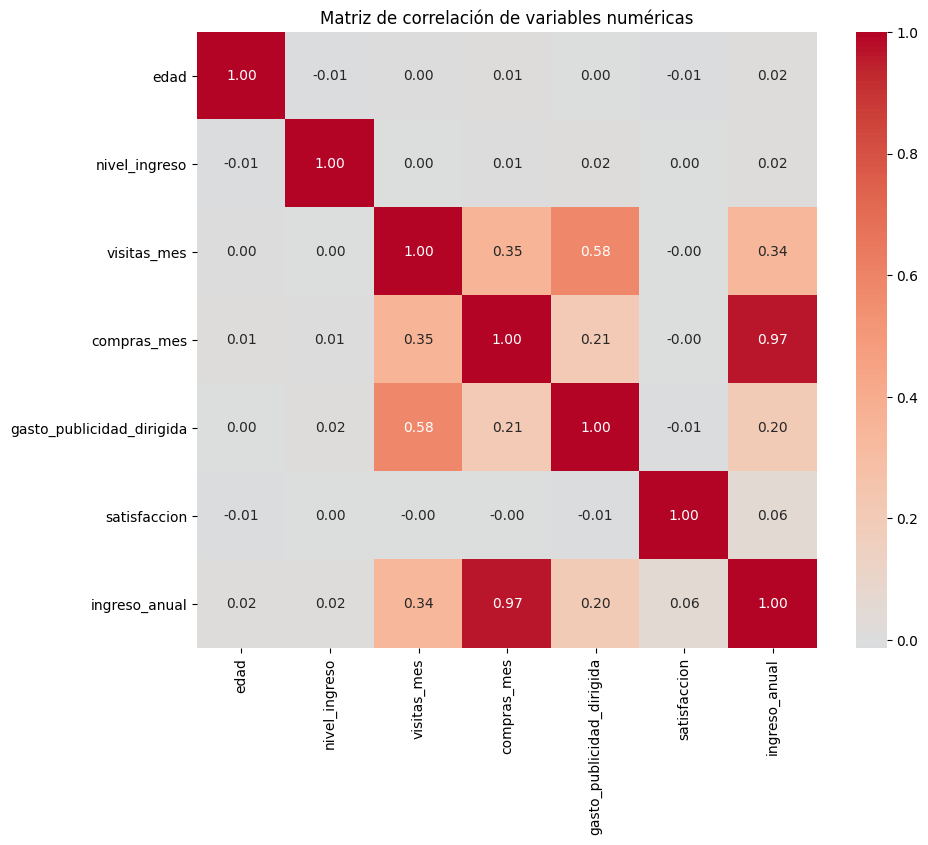

In [47]:
# Visualizar la matriz de correlación para identificar relaciones

plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación de variables numéricas")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   

Incluye qué ves

Respuesta: 
Observaciones generales (Heatmap)

Se observa una matriz de correlación de Pearson para 7 variables numéricas donde la mayoría de los pares de variables muestran valores cercanos a 0.00 (color gris), lo que señala una nula correlación lineal entre la mayoría de las métricas (como edad, nivel_ingreso y satisfaccion).

Se identifican interacciones positivas moderadas entre el comportamiento de navegación y la interacción publicitaria: gasto_publicidad_dirigida se relaciona moderadamente con visitas_mes (0.58) y de forma leve con compras_mes (0.21).

Observaciones respecto a ingreso_anual

Presenta una correlación positiva casi perfecta con compras_mes (0.97), lo que indica que a mayor número de compras mensuales, mayor es el ingreso anual registrado.

Muestra correlaciones positivas moderadas a leves con visitas_mes (0.34) y gasto_publicidad_dirigida (0.20), mientras que con edad, nivel_ingreso y satisfaccion no muestra relación alguna (valores entre 0.02 y 0.06).



### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
Respuesta: Yo no lo podría ya que resultaría ineficiente y poco informativo.

### Scatterplot para pares clave

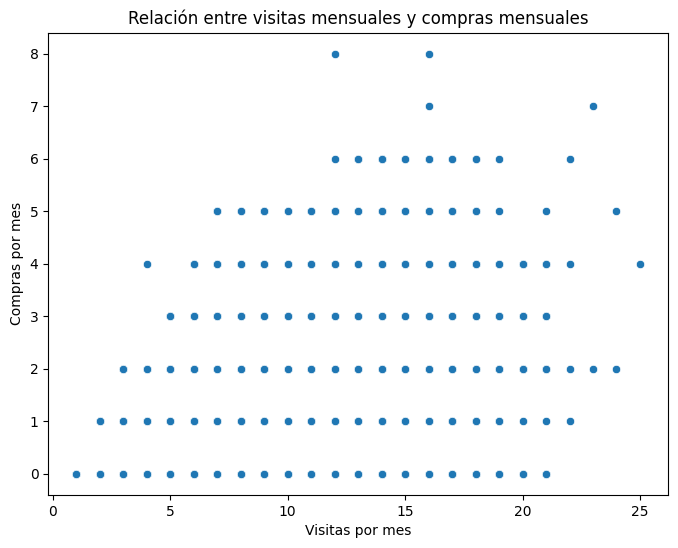

In [44]:
# Visualizar pares de variables con relaciones moderadas o fuertes

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="compras_mes"
)

plt.title("Relación entre visitas mensuales y compras mensuales")
plt.xlabel("Visitas por mes")
plt.ylabel("Compras por mes")
plt.show()

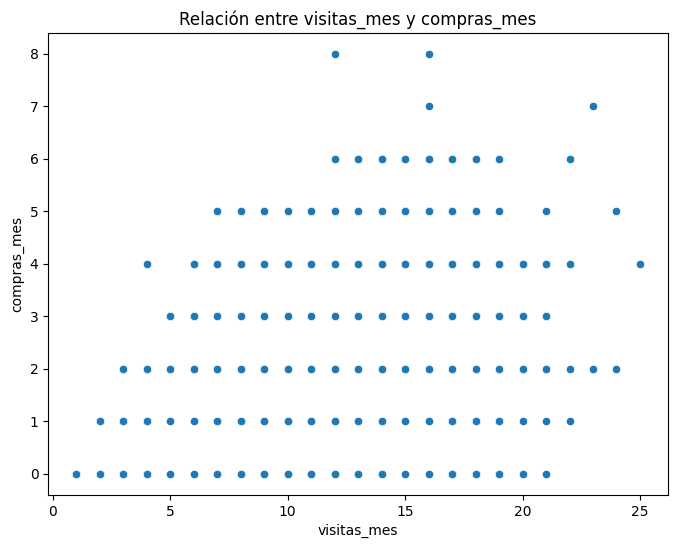

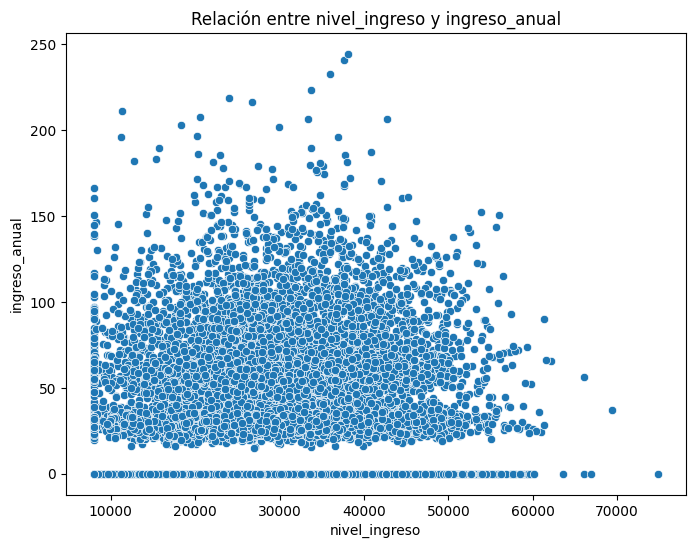

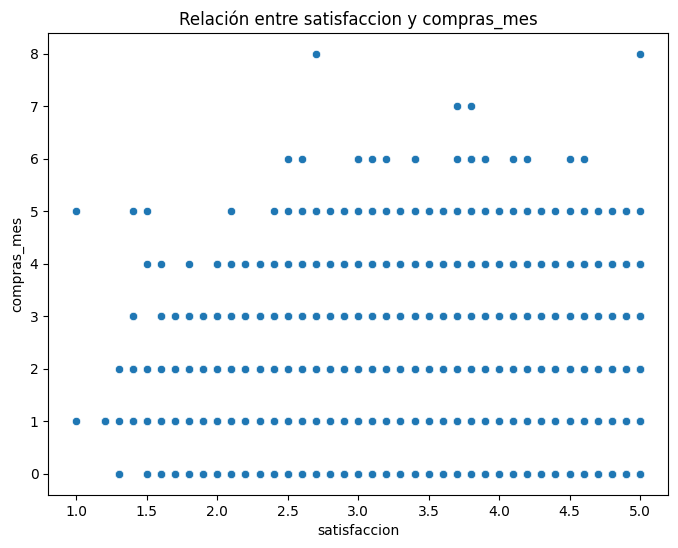

In [45]:
# Pares de variables con correlaciones moderadas o fuertes
pares = [
    ("visitas_mes", "compras_mes"),
    ("nivel_ingreso", "ingreso_anual"),
    ("satisfaccion", "compras_mes")
]

for x, y in pares:
    plt.figure(figsize=(8, 6))
    
    sns.scatterplot(
        data=df,
        x=x,
        y=y
    )
    
    plt.title(f"Relación entre {x} y {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

visitas_mes vs. compras_mes

Dirección: Positiva (a mayor número de visitas, se observa una leve tendencia a realizar más compras).

Dispersión: Alta (los datos forman una nube bastante extendida horizontal y verticalmente).

Presencia de outliers: Sí, se observan valores atípicos aislados en la parte superior (usuarios con 7 y 8 compras al mes, alejados de la concentración principal de 0 a 3 compras).
Posible colinealidad: No presenta multicolinealidad severa; existe una relación lineal moderada

satisfaccion vs. compras_mes
Dirección: Nula o neutra (los puntos están distribuidos uniformemente a lo largo de toda la escala de satisfacción).
Dispersión: Muy alta (distribución dispersa y en red uniforme).
Presencia de outliers: Sí, destacan los puntos aislados con 8 compras mensuales (en niveles de satisfacción de 2.7 y 5.0).
Posible colinealidad: No existe colinealidad alguna, indicando que son variables totalmente independientes.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. El heatmap está correctamente generado y la decisión de no crear un scatterplot general está bien justificada. Sin embargo, los scatterplots para pares clave no corresponden a los dos pares principales. Debes visualizar directamente `compras_mes` vs `ingreso_anual` y `visitas_mes` vs `ingreso_anual`.

</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [46]:
# Calcular correlación entre variables relevantes pearson

variables_numericas = df.select_dtypes(include="number")


correlacion_pearson = variables_numericas.corr(method="pearson")


correlacion_pearson.round(2)

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.00,-0.01,0.00,0.01,0.00,-0.01,0.02
nivel_ingreso,-0.01,1.00,0.00,0.01,0.02,0.00,0.02
visitas_mes,0.00,0.00,1.00,0.35,0.58,-0.00,0.34
compras_mes,0.01,0.01,0.35,1.00,0.21,-0.00,0.97
gasto_publicidad_dirigida,0.00,0.02,0.58,0.21,1.00,-0.01,0.20
satisfaccion,-0.01,0.00,-0.00,-0.00,-0.01,1.00,0.06
ingreso_anual,0.02,0.02,0.34,0.97,0.20,0.06,1.00


In [48]:
# Calcular correlación entre variables relevantes

correlacion_spearman = variables_numericas.corr(method="spearman")


correlacion_spearman.round(2)

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.00,-0.01,0.01,0.02,0.00,-0.01,0.02
nivel_ingreso,-0.01,1.00,0.00,0.01,0.02,0.01,0.03
visitas_mes,0.01,0.00,1.00,0.33,0.56,-0.00,0.32
compras_mes,0.02,0.01,0.33,1.00,0.19,-0.00,0.97
gasto_publicidad_dirigida,0.00,0.02,0.56,0.19,1.00,-0.01,0.18
satisfaccion,-0.01,0.01,-0.00,-0.00,-0.01,1.00,0.06
ingreso_anual,0.02,0.03,0.32,0.97,0.18,0.06,1.00


In [49]:


print("CORRELACIÓN DE PEARSON")
display(correlacion_pearson.round(2))

print("\nCORRELACIÓN DE SPEARMAN")
display(correlacion_spearman.round(2))

CORRELACIÓN DE PEARSON


,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.00,-0.01,0.00,0.01,0.00,-0.01,0.02
nivel_ingreso,-0.01,1.00,0.00,0.01,0.02,0.00,0.02
visitas_mes,0.00,0.00,1.00,0.35,0.58,-0.00,0.34
compras_mes,0.01,0.01,0.35,1.00,0.21,-0.00,0.97
gasto_publicidad_dirigida,0.00,0.02,0.58,0.21,1.00,-0.01,0.20
satisfaccion,-0.01,0.00,-0.00,-0.00,-0.01,1.00,0.06
ingreso_anual,0.02,0.02,0.34,0.97,0.20,0.06,1.00



CORRELACIÓN DE SPEARMAN


,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
edad,1.00,-0.01,0.01,0.02,0.00,-0.01,0.02
nivel_ingreso,-0.01,1.00,0.00,0.01,0.02,0.01,0.03
visitas_mes,0.01,0.00,1.00,0.33,0.56,-0.00,0.32
compras_mes,0.02,0.01,0.33,1.00,0.19,-0.00,0.97
gasto_publicidad_dirigida,0.00,0.02,0.56,0.19,1.00,-0.01,0.18
satisfaccion,-0.01,0.01,-0.00,-0.00,-0.01,1.00,0.06
ingreso_anual,0.02,0.03,0.32,0.97,0.18,0.06,1.00


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

compras_mes vs. ingreso_anual
Correlación de Pearson: 0.97
Correlación de Spearman: 0.97
Dirección: Positiva.Magnitud: 
Muy alta / Casi perfecta.
Posible colinealidad: Sí, presenta colinealidad severa. Un coeficiente de 0.97 indica una redundancia casi total entre ambas variables; si se utilizan juntas en un modelo de regresión, generarán problemas graves de multicolinealidad.
gasto_publicidad_dirigida vs. visitas_mesCorrelación de Pearson: 0.58
Correlación de Spearman: 0.56
Dirección: Positiva.
Magnitud: Moderada.
Posible colinealidad: No presenta colinealidad crítica, aunque existe una asociación lineal moderada y consistente entre la pauta publicitaria y la frecuencia de visitas.
visitas_mes vs. compras_mes
Correlación de Pearson: 0.35
Correlación de Spearman: 0.33
Dirección: Positiva.
Magnitud: Debil a moderada.
Posible colinealidad: No presenta riesgo de colinealidad.
visitas_mes vs. ingreso_anual
Correlación de Pearson: 0.34
Correlación de Spearman: 0.32
Dirección: Positiva.
Magnitud: Debil a moderada
Posible colinealidad: No presenta riesgo de colinealidad.
gasto_publicidad_dirigida vs. compras_mes
Correlación de Pearson: 0.21
Correlación de Spearman: 0.19
Dirección: Positiva.
Magnitud: Débil
Posible colinealidad: No presenta riesgo de colinealidad.

### Punto-biserial

In [50]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr


variables_binarias = ["miembro_premium", "abandono"]


variables_numericas = [
    "edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]


for binaria in variables_binarias:
    
    print("=" * 60)
    print(f"Variable binaria: {binaria}")
    
    for numerica in variables_numericas:
        
    
        datos = df[[binaria, numerica]].dropna()
        
       
        correlacion, p_valor = pointbiserialr(
            datos[binaria],
            datos[numerica]
        )
        
        print(
            f"{numerica:30} "
            f"r = {correlacion:.3f} | "
            f"p-valor = {p_valor:.4f}"
        )

Variable binaria: miembro_premium
edad                           r = 0.005 | p-valor = 0.5728
nivel_ingreso                  r = -0.006 | p-valor = 0.4930
visitas_mes                    r = -0.013 | p-valor = 0.1211
compras_mes                    r = 0.003 | p-valor = 0.6744
gasto_publicidad_dirigida      r = 0.003 | p-valor = 0.7390
satisfaccion                   r = 0.026 | p-valor = 0.0016
ingreso_anual                  r = 0.093 | p-valor = 0.0000
Variable binaria: abandono
edad                           r = -0.012 | p-valor = 0.1590
nivel_ingreso                  r = 0.006 | p-valor = 0.4722
visitas_mes                    r = -0.009 | p-valor = 0.2734
compras_mes                    r = 0.008 | p-valor = 0.3099
gasto_publicidad_dirigida      r = -0.005 | p-valor = 0.5744
satisfaccion                   r = -0.024 | p-valor = 0.0035
ingreso_anual                  r = -0.003 | p-valor = 0.7295


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial
Variable binaria: miembro_premiummiembro_premium vs. ingreso_anual
Relación: Estadísticamente significativa .
Dirección: Positiva .
Magnitud: Baja.
miembro_premium vs. satisfaccion
Relación: Estadísticamente significativa .
Dirección: Positiva .
Magnitud: Muy baja / Prácticamente nula.
miembro_premium vs. visitas_mes
Relación: No es estadísticamente significativa .
Dirección: Negativa .
Magnitud: Nula.
miembro_premium vs. edad
Relación: No es estadísticamente significativa .
Dirección: Positiva 
Magnitud: Nula.
miembro_premium vs. nivel_ingreso
Relación: No es estadísticamente significativa .
Dirección: Negativa 
Magnitud: Nula.
miembro_premium vs. compras_mes / gasto_publicidad_dirigida
Relación: No son estadísticamente significativas .
Dirección: Positiva .
Magnitud: Nula.
Variable binaria: abandono
abandono vs. satisfaccion
Relación: Estadísticamente significativa .
Dirección: Negativa .
Magnitud: Muy baja / Prácticamente nula.
abandono vs. edad
Relación: No es estadísticamente significativa 
Dirección: Negativa 
Magnitud: Nula.
abandono vs. visitas_mes
Relación: No es estadísticamente significativa 
Dirección: Negativa 
Magnitud: Nula.
abandono vs. compras_mes
Relación: No es estadísticamente significativa 
Dirección: Positiva 
Magnitud: Nula.
abandono vs. nivel_ingreso
Relación: No es estadísticamente significativa 
Dirección: Positiva 
Magnitud: Nula.
abandono vs. gasto_publicidad_dirigida
Relación: No es estadísticamente significativa 
Dirección: Negativa 
Magnitud: Nula.
abandono vs. ingreso_anual
Relación: No es estadísticamente significativa 
Dirección: Negativa 
Magnitud: Nula.

### V de Cramér

In [51]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """
    Calcula V de Cramér entre dos variables categóricas.
    """
    
    
    tabla = pd.crosstab(x, y)
    
    
    chi2 = chi2_contingency(tabla)[0]
    
    
    n = tabla.sum().sum()
    
    
    r, k = tabla.shape
    
    
    phi2 = chi2 / n
    
    v = np.sqrt(phi2 / min(k - 1, r - 1))
    
    return v

In [52]:
# Aplicar V de Cramér en variables relevantes
variables_categoricas = [
    "tipo_dispositivo",
    "region",
    "miembro_premium",
    "abandono"
]

for i in range(len(variables_categoricas)):
    for j in range(i + 1, len(variables_categoricas)):
        
        var1 = variables_categoricas[i]
        var2 = variables_categoricas[j]
        
       
        datos = df[[var1, var2]].dropna()
        
       
        v = cramers_v(datos[var1], datos[var2])
        
        print(f"{var1} ↔ {var2}: V de Cramér = {v:.3f}")


tipo_dispositivo ↔ region: V de Cramér = 0.012
tipo_dispositivo ↔ miembro_premium: V de Cramér = 0.020
tipo_dispositivo ↔ abandono: V de Cramér = 0.007
region ↔ miembro_premium: V de Cramér = 0.013
region ↔ abandono: V de Cramér = 0.015
miembro_premium ↔ abandono: V de Cramér = 0.120


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

miembro_premium vs. abandonoMagnitud: Baja a moderada .
Asociación: Es el par categórico que presenta la asociación más fuerte de todo el grupo, indicando que la condición de membresía premium tiene una relación observable con la probabilidad de abandono.
tipo_dispositivo vs. miembro_premium
Magnitud: Muy baja / Insignificante 
Asociación: Practicamente nula; el tipo de dispositivo que utiliza el usuario no se relaciona con si cuenta o no con membresía premium.
region vs. abandono
Magnitud: Muy baja / Insignificante 
Asociación: No existe asociación relevante entre la región geográfica del usuario y la tasa de abandono.
region vs. miembro_premium
Magnitud: Muy baja / Insignificante 
Asociación: La distribución de usuarios premium es uniforme independientemente de la región.
tipo_dispositivo vs. region
Magnitud: Muy baja / Insignificante 
Asociación: La preferencia de dispositivo no varía significativamente según la región del usuario.
tipo_dispositivo vs. abandono
Magnitud: Nula / Insignificante 
Asociación: El tipo de dispositivo no influye en la propensión del usuario a abandonar la plataforma.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Las matrices de Pearson y Spearman contienen correctamente los valores necesarios para los dos pares principales: `compras_mes` vs `ingreso_anual` ≈ 0.967/0.967 y `visitas_mes` vs `ingreso_anual` ≈ 0.337/0.321.

</div>

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — 

En el punto 3.3. Scatterplot para pares clave, Podemos ver el siguiente gráfico con las siguientes características:
Análisis de relación: visitas_mes vs. compras_mes
Evidencia visual: Nube de puntos (scatterplot) con una dirección levemente ascendente de izquierda a derecha.
Alta dispersión vertical: para un mismo nivel de visitas mensuales, existe una gran variación en el número de compras.
Evidencia numérica:
Correlación de Pearson  0.35 (asociación positiva moderada-baja).
Correlación de Spearman 0.33 (asociación monótona moderada-baja).
Rango de variables: visitas_mes entre 1 y 25; compras_mes entre 0 y 8.
Interpretación (no causal)
Existe una asociación positiva leve a moderada entre ambas variables: los usuarios que frecuentan más el sitio o aplicación tienden, en promedio, a registrar un número ligeramente mayor de compras al mes.
No podemos afirmar
Causalidad: No podemos afirmar que aumentar el número de visitas de un usuario generará automáticamente más compras.
Implicación de negocio
Optimización del embudo de conversión: Traer más tráfico o lograr que el usuario visite más veces la plataforma no es suficiente por sí solo para asegurar la venta. El foco del equipo debe estar en reducir la fricción en el proceso de compra.

### Hallazgo 2 — 

En el punto 3.3. Scatterplot para pares clave, Podemos ver el siguiente gráfico con las siguientes características:
Análisis de relación: satisfaccion vs. compras_mes
Evidencia visual
Nube de puntos (scatterplot) con una distribución rectangular y totalmente uniforme, sin inclinación ni tendencia hacia arriba o hacia abajo.
Evidencia numérica
Rango de variables: satisfaccion de 1.0 a 5.0; compras_mes de 0 a 8.
nterpretación (no causal)
Existe una independencia práctica entre ambas variables: la satisfacción expresada por el usuario no muestra ninguna asociación lineal ni tendencia con respecto al número de compras mensuales que realiza.
No podemos afirmar
Que los clientes insatisfechos dejen de comprar: Hay usuarios con bajos puntajes de satisfacción que mantienen un volumen recurrente de compras mensuales.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Sin embargo. El Hallazgo 1 debe centrarse en `compras_mes` vs `ingreso_anual`, con Pearson y Spearman ≈ 0.967, y el Hallazgo 2 en `visitas_mes` vs `ingreso_anual`, con Pearson ≈ 0.337 y Spearman ≈ 0.321.

</div>

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**

Correlación ≠ causalidad: las relaciones observadas (por ejemplo, entre gasto en publicidad dirigida, satisfacción o visitas y el abandono) no implican una relación causal directa; podrían existir variables externas no capturadas en el dataset.
No se cuenta con variables temporales (fecha de registro, antigüedad del cliente) que permitan análisis de cohortes o series de tiempo.
### **Próximos pasos** 

Probar segmentación adicional
Segmentar por combinación de región y tipo de dispositivo (móvil, escritorio, tablet) para identificar patrones de comportamiento diferenciados.

Modelado predictivo de abandono

Construir un modelo de clasificación (regresión logística, random forest o gradient boosting) para predecir la probabilidad de abandono, aplicando técnicas de balanceo de clases.

Validación causal

Diseñar experimentos controlados sobre publicidad dirigida y beneficios premium para confirmar relaciones causales sobre retención y satisfacción


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Felicitaciones, los hallazgos son claros y directos. Esto es muy importante
para cualquier analista de datos, ya que no alcanza solo con obtener números, también debemos ser
capaces de comunicar cómo esos números impactan en el negocio.

Felicitaciones por el trabajo realizado. Si bien hay algunos puntos de mejora, el proyecto está en
condiciones de ser aprobado.

¡Mucho éxito en tu camino dentro del mundo de los datos!


</div>
